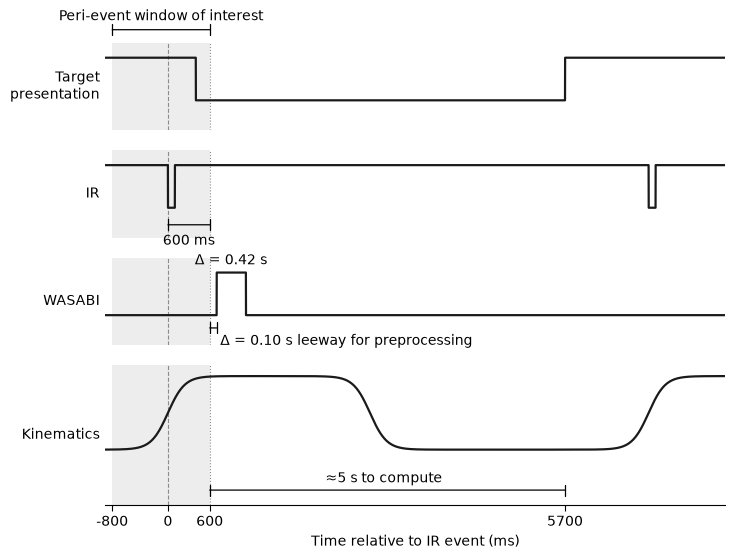

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Timing parameters in seconds, t = 0 at the IR event
T_TP_ON, T_TP_OFF = -1.2, 0.4
T_IR = 0.0
IR_OFF_DUR = 0.1
WIN_START, WIN_END = -0.8, 0.6
WT_LEEWAY = 0.1
WT_DUR = 0.42
SPAN = 5.0
T_START, T_END = -0.9, 8

wt_on = WIN_END + WT_LEEWAY
wt_off = wt_on + WT_DUR
tp_off = T_TP_OFF
next_tp_on = wt_on + SPAN
next_ir = next_tp_on + (T_IR - T_TP_ON)

t = np.linspace(T_START, T_END, 5000)


def pulse(on, off):
    return ((t >= on) & (t < off)).astype(float)


def sig(t0, tau):
    return 1 / (1 + np.exp(-(t - t0) / tau))


tp = pulse(T_TP_ON, tp_off) + pulse(next_tp_on, np.inf)
ir = 1 - pulse(T_IR, T_IR + IR_OFF_DUR) - pulse(next_ir, next_ir + IR_OFF_DUR)
wt = pulse(wt_on, wt_off)
kin = sig(T_IR, 0.12) - sig(2.9, 0.12) + sig(next_ir, 0.12)

plt.rcParams.update({"font.size": 10, "font.family": "sans-serif"})
fig, axes = plt.subplots(
    4, 1, sharex=True, figsize=(8, 6),
    gridspec_kw=dict(height_ratios=[1, 1, 1, 1.6], hspace=0.2),
)
signals = [(tp, "Target\npresentation"), (ir, "IR"), (wt, "WASABI"), (kin, "Kinematics")]
color = "0.1"
bracket = dict(arrowstyle="|-|", lw=0.9, mutation_scale=4, shrinkA=0, shrinkB=0)

for ax, (y, label) in zip(axes, signals):
    ax.plot(t, y, color=color, lw=1.6)
    ax.set_ylabel(label, rotation=0, ha="right", va="center")
    ax.set_yticks([])
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_visible(False)
    ax.tick_params(axis="x", length=0)
    ax.axvspan(WIN_START, WIN_END, color="0.93", lw=0, zorder=-1)
    ax.axvline(T_IR, ls="--", lw=0.8, color="0.55", zorder=0)
    ax.axvline(WIN_END, ls=":", lw=0.8, color="0.55", zorder=0)
    ax.axvline(T_TP_ON, ls=":", lw=0.8, color="0.55", zorder=0)

for ax in axes[:3]:
    ax.set_ylim(-0.7, 1.35)

# Peri-event window label above the top row
ax = axes[0]
ax.annotate("", xy=(WIN_START, 1.15), xytext=(WIN_END, 1.15), xycoords=("data", "axes fraction"),
            textcoords=("data", "axes fraction"), arrowprops=bracket, annotation_clip=False)
ax.text((WIN_START + WIN_END) / 2, 1.22, "Peri-event window of interest", ha="center", va="bottom",
        transform=ax.get_xaxis_transform())
fig.subplots_adjust(top=0.88)

# IR to end of window
ax = axes[1]
ax.annotate("", xy=(T_IR, -0.4), xytext=(WIN_END, -0.4), arrowprops=bracket)
ax.text((T_IR + WIN_END) / 2, -0.62, f"{(WIN_END - T_IR) * 1000:.0f} ms", ha="center", va="top")

# WASABI leeway and duration labels
ax = axes[2]
ax.annotate("", xy=(WIN_END, -0.3), xytext=(wt_on, -0.3), arrowprops=bracket)
ax.text(wt_on + 0.05, -0.45, rf"$\Delta$ = {WT_LEEWAY:.2f} s leeway for preprocessing", ha="left", va="top")
ax.text((wt_on + wt_off) / 2, 1.1, rf"$\Delta$ = {WT_DUR:.2f} s", ha="center", va="bottom")

# Span arrow under kinematics
ax = axes[3]
ax.set_ylim(-0.75, 1.15)
ax.annotate("", xy=(WIN_END, -0.55), xytext=(wt_on + SPAN, -0.55), arrowprops=bracket)
ax.text(WIN_END + SPAN / 2, -0.49, f"≈{SPAN:g} s to compute", ha="center", va="bottom")

ax.spines["bottom"].set_visible(True)
ax.tick_params(axis="x", length=4)
ax.set_xticks([WIN_START, T_TP_ON, T_IR, WIN_END, next_tp_on])
ax.set_xticklabels([f"{x * 1000:.0f}" for x in ax.get_xticks()])
ax.set_xlim(T_START, T_END)
ax.set_xlabel("Time relative to IR event (ms)")

fig.savefig("task_timing.svg", bbox_inches="tight")
plt.show()

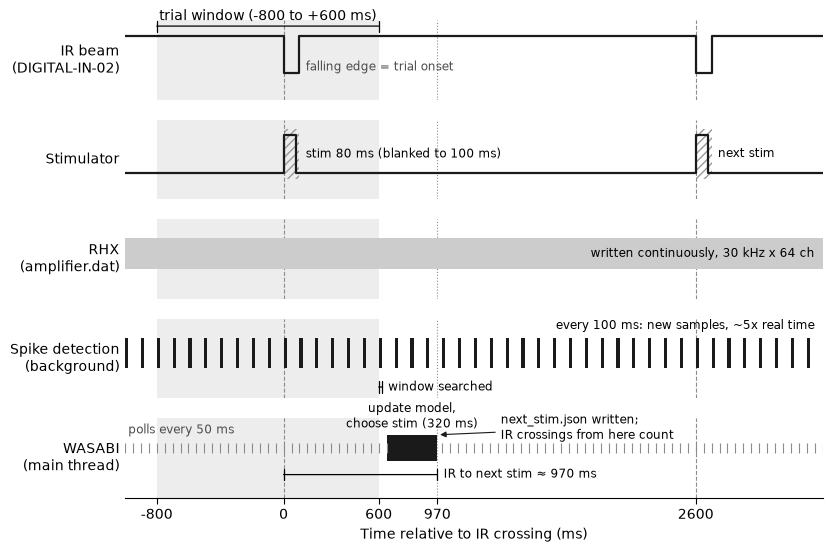

In [1]:
# Hardware / software timing of one closed-loop trial in wasabi_online (IR trigger)
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

sys.path.insert(0, str(Path.cwd().parent / "experiment" / "src"))
from config_loading import load_config

cfg = load_config()
WIN_START, WIN_END = (w / 1000 for w in cfg.trial.window_ms)  # trial window around the IR crossing
STIM_S = cfg.stim.stim_ms / 1000
BLANK_END = STIM_S + cfg.stim.blank_after_ms / 1000
IR_CH = cfg.session.trigger if cfg.session.trigger not in ("keypress", "auto") else cfg.trial.ir_channel

# Loop timing: polling intervals from the code, durations as measured in a live test
DETECT_POLL = 0.1  # background thread looks for new samples (IntanStream.start)
DETECT_SPEED = 5.0  # spike detection, x real time
MAIN_POLL = 0.05  # main thread checks for a complete trial (IR trigger)
UPDATE_S = 0.04 + 0.28  # acquisition (choose stim) + fitting (EKF and refit) per trial
IR_LOW_S = 0.1  # beam blocked
NEXT_IR = 2.6  # next reach
T_START, T_END = -1.0, 3.4

# Derived events
detect_blocks = [(t, DETECT_POLL / DETECT_SPEED) for t in
                 [WIN_START - 0.2 + DETECT_POLL * k for k in range(int((T_END - WIN_START + 0.2) / DETECT_POLL))]]
searched = min(t + d for t, d in detect_blocks if t >= WIN_END)  # window searched for spikes
found = MAIN_POLL * (int(searched / MAIN_POLL) + 1)  # next poll of the main thread
decided = found + UPDATE_S  # next stim written to next_stim.json, IR armed

plt.rcParams.update({"font.size": 10, "font.family": "sans-serif"})
fig, axes = plt.subplots(5, 1, sharex=True, figsize=(9, 6.2),
                         gridspec_kw=dict(height_ratios=[1, 1, 1, 1, 1], hspace=0.25))
labels = [f"IR beam\n({IR_CH})", "Stimulator", "RHX\n(amplifier.dat)", "Spike detection\n(background)",
          "WASABI\n(main thread)"]
ink, muted = "0.1", "0.55"
bracket = dict(arrowstyle="|-|", lw=0.9, mutation_scale=4, shrinkA=0, shrinkB=0)

for ax, label in zip(axes, labels):
    ax.set_ylabel(label, rotation=0, ha="right", va="center")
    ax.set_yticks([])
    ax.set_ylim(-0.7, 1.4)
    for side in ("top", "right", "left", "bottom"):
        ax.spines[side].set_visible(False)
    ax.tick_params(axis="x", length=0)
    ax.axvspan(WIN_START, WIN_END, color="0.93", lw=0, zorder=-1)
    for x in (0, NEXT_IR):
        ax.axvline(x, ls="--", lw=0.8, color=muted, zorder=0)
    ax.axvline(decided, ls=":", lw=0.8, color=muted, zorder=0)

# IR: high, falls when the beam is crossed
ax = axes[0]
ax.step([T_START, 0, IR_LOW_S, NEXT_IR, NEXT_IR + IR_LOW_S, T_END], [1, 0, 1, 0, 1, 1], where="post", color=ink, lw=1.6)
ax.text(IR_LOW_S + 0.04, 0.0, "falling edge = trial onset", ha="left", va="bottom", fontsize=8.5, color="0.3")
ax.annotate("", xy=(WIN_START, 1.25), xytext=(WIN_END, 1.25), arrowprops=bracket, annotation_clip=False)
ax.text((WIN_START + WIN_END) / 2, 1.32, f"trial window ({WIN_START * 1000:.0f} to +{WIN_END * 1000:.0f} ms)",
        ha="center", va="bottom")

# Stimulator: the stim in next_stim.json, from the IR crossing; blanked through blank_after_ms
ax = axes[1]
ax.step([T_START, 0, STIM_S, NEXT_IR, NEXT_IR + STIM_S, T_END], [0, 1, 0, 1, 0, 0], where="post", color=ink, lw=1.6)
for x0 in (0, NEXT_IR):
    ax.add_patch(Rectangle((x0, -0.15), BLANK_END, 1.3, fill=False, hatch="////", lw=0, ec="0.6", zorder=-0.5))
ax.text(BLANK_END + 0.04, 0.5, f"stim {cfg.stim.stim_ms:g} ms (blanked to {BLANK_END * 1000:.0f} ms)",
        ha="left", va="center", fontsize=8.5)
ax.text(NEXT_IR + BLANK_END + 0.04, 0.5, "next stim", ha="left", va="center", fontsize=8.5)

# RHX writes continuously
ax = axes[2]
ax.add_patch(Rectangle((T_START, 0.1), T_END - T_START, 0.8, color="0.8", lw=0))
ax.text(T_END - 0.05, 0.5, f"written continuously, {cfg.recording.sample_rate / 1000:g} kHz x {cfg.recording.num_channels} ch",
        ha="right", va="center", fontsize=8.5)

# Background thread: every poll, reads the new samples and detects spikes in them
ax = axes[3]
for t, d in detect_blocks:
    ax.add_patch(Rectangle((t, 0.1), d, 0.8, color=ink, lw=0))
ax.annotate("", xy=(WIN_END, -0.4), xytext=(searched, -0.4), arrowprops=bracket)
ax.text(searched + 0.04, -0.4, "window searched", ha="left", va="center", fontsize=8.5)
ax.text(T_END - 0.05, 1.05, f"every {DETECT_POLL * 1000:.0f} ms: new samples, ~{DETECT_SPEED:g}x real time",
        ha="right", va="bottom", fontsize=8.5)

# Main thread: polls for a complete trial, updates the model, writes the next stim
ax = axes[4]
polls = [MAIN_POLL * k for k in range(int(T_START / MAIN_POLL), int(T_END / MAIN_POLL) + 1)
         if not found < MAIN_POLL * k < decided]
ax.vlines(polls, 0.35, 0.65, color=muted, lw=0.8)
ax.add_patch(Rectangle((found, 0.1), UPDATE_S, 0.8, color=ink, lw=0))
ax.text(found + UPDATE_S / 2, 1.0, f"update model,\nchoose stim ({UPDATE_S * 1000:.0f} ms)", ha="center", va="bottom", fontsize=8.5)
ax.annotate("next_stim.json written;\nIR crossings from here count", xy=(decided, 0.9), xytext=(decided + 0.4, 1.1),
            ha="left", va="center", fontsize=8.5, arrowprops=dict(arrowstyle="-|>", lw=0.8, color=ink))
ax.set_ylim(-1.0, 1.4)
ax.annotate("", xy=(0, -0.3), xytext=(decided, -0.3), arrowprops=bracket)
ax.text(decided + 0.04, -0.3, f"IR to next stim ≈ {decided * 1000:.0f} ms", ha="left", va="center", fontsize=8.5)
ax.text(T_START + 0.02, 0.85, f"polls every {MAIN_POLL * 1000:.0f} ms", ha="left", va="bottom", fontsize=8.5, color="0.3")

ax.spines["bottom"].set_visible(True)
ax.tick_params(axis="x", length=4)
ax.set_xticks([WIN_START, 0, WIN_END, decided, NEXT_IR])
ax.set_xticklabels([f"{x * 1000:.0f}" for x in ax.get_xticks()])
ax.set_xlim(T_START, T_END)
ax.set_xlabel("Time relative to IR crossing (ms)")

fig.savefig("wasabi_online_timing.svg", bbox_inches="tight")
plt.show()